# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Agnetha Giselle
- **Email:** agnethagisellegwee@gmail.com
- **ID Dicoding:** ds008b6x0072

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1**: Stasiun mana yang paling tercemar pada setiap tahun antara 2014-2016, dan seberapa besar tingkat perbaikannya?
- **Pertanyaan 2:** Ada bulan dan jam berapa kadar PM2.5 paling sering melampaui 150 µg/m³?
- **Pertanyaan 3:** Bagaimana hubungan antara angin dan hujan dengan kadar PM2.5 pada musim dingin dibandingkan dengan musim panas?

## Import Semua Packages/Library yang Digunakan

In [ ]:
%pip install streamlit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import streamlit

## Data Wrangling

### Gathering Data

#### Load df ...

In [ ]:
autizhongxin_df = pd.read_csv("PRSA_Data_Aotizhongxin_20130301-20170228.csv")
changping_df = pd.read_csv("PRSA_Data_Changping_20130301-20170228.csv")
dingling_df = pd.read_csv("PRSA_Data_Dingling_20130301-20170228.csv")
dongsi_df = pd.read_csv("PRSA_Data_Dongsi_20130301-20170228.csv")
guanyuan_df = pd.read_csv("PRSA_Data_Guanyuan_20130301-20170228.csv")
guacheng_df = pd.read_csv("PRSA_Data_Gucheng_20130301-20170228.csv")
huairou_df = pd.read_csv("PRSA_Data_Huairou_20130301-20170228.csv")
nongzhanguan_df = pd.read_csv("PRSA_Data_Nongzhanguan_20130301-20170228.csv")
shunyin_df = pd.read_csv("PRSA_Data_Shunyi_20130301-20170228.csv")
tiantan_df = pd.read_csv("PRSA_Data_Tiantan_20130301-20170228.csv")
wanliu_df = pd.read_csv("PRSA_Data_Wanliu_20130301-20170228.csv")
wanshouxigong_df = pd.read_csv("PRSA_Data_Wanshouxigong_20130301-20170228.csv")

In [ ]:
df_raw = pd.concat([autizhongxin_df, changping_df, dingling_df, dongsi_df, guanyuan_df, guacheng_df,huairou_df, nongzhanguan_df, shunyin_df, tiantan_df, wanliu_df, wanshouxigong_df],ignore_index=True)
df_raw.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:** (Opsional)
- Pada jam-jam awal ini kualitas udara tergolong baik: PM2.5 hanya 3-8 µg/m^3 dan hujan 0 mm. Suhu dingin -0,7 hingga -2,0 °C dan angin bertiup dari arah N/NW/NNW dengan kecepatan 2,0-5,6 m/s.
- Kolom "station" menunjukkan asal data tiap baris, sehingga data antar stasiun tetap bisa dibandingkan setelah digabung. Kolom "No" hanya nomor urut baris dan tidak dipakai dalam analisis.
- Lima baris pertama berasal dari stasiun Aotizhongxin pada 1 Maret 2013, pukul 00:00-04:00. Ini menunjukkan data dicatat per jam dan sudah berurutan.

### Assessing Data

#### Identifying ... problem

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


In [ ]:
df_raw.isna().sum()

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,8739
PM10,6449
SO2,9021
NO2,12116
CO,20701


In [ ]:
print("Jumlah duplikasi: ", df_raw.duplicated().sum())

Jumlah duplikasi:  0


In [ ]:
df_raw.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


In [ ]:
n = (df_raw['PM2.5'] > df_raw['PM10']).sum()
print(f'Baris dengan PM2.5 > PM10: {n:,} ({n/len(df_raw)*100:.1f}%)')

Baris dengan PM2.5 > PM10: 21,312 (5.1%)


In [ ]:
q1, q3 = df_raw['PM2.5'].quantile([0.25, 0.75])
batas = q3 + 1.5*(q3 - q1)
print(f'Batas atas IQR = {batas:.1f}; baris di atasnya: {(df_raw["PM2.5"] > batas).sum():,}')

Batas atas IQR = 247.5; baris di atasnya: 19,142


**Steps to Take:**
- Inconsistent value (PM2.5 > PM10): samakan PM10 dengan PM2.5 pada baris tersebut, karena PM10 mencakup PM2.5.
- Outlier: tidak dihapus, karena konsentrasi tinggi adalah episode polusi nyata yang menjadi inti pertanyaan analisis.
- Duplikat: tidak ada, jadi tidak perlu tindakan.
- Missing value: polutan (PM2.5, PM10, SO2, NO2, CO, O3) dan RAIN diisi dengan median kolom, variabel cuaca kontinu (TEMP, PRES, DEWP, WSPM) diisi dengan interpolasi linear, dan arah angin (`wd`) diisi dengan modus.

**Insight:** (Opsional)
- Tidak ada baris duplikat.
- Ada 21.312 baris (5,1%) dengan PM2.5 > PM10, yang secara fisik tidak mungkin dan perlu diperbaiki.
- 19.142 pembacaan PM2.5 berada di atas batas IQR, dan nilai maksimum mencapai 999 (kemungkinan batas alat ukur). Nilai ini tetap dipertahankan sebagai episode polusi ekstrem.

### Cleaning Data

#### Fixing ... problem

In [ ]:
df_raw.drop_duplicates(inplace=True)
print("Jumlah duplikasi: ", df_raw.duplicated().sum())

Jumlah duplikasi:  0


In [ ]:
df_raw["PM2.5"].value_counts()
df_raw["PM2.5"] = df_raw["PM2.5"].fillna(df_raw["PM2.5"].median())
print("Missing values:", df_raw["PM2.5"].isna().sum())
print("Missing percentage:", df_raw["PM2.5"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["PM10"].value_counts()
df_raw["PM10"] = df_raw["PM10"].fillna(df_raw["PM10"].median())
print("Missing values:", df_raw["PM10"].isna().sum())
print("Missing percentage:", df_raw["PM10"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["SO2"].value_counts()
df_raw["SO2"] = df_raw["SO2"].fillna(df_raw["SO2"].median())
print("Missing values:", df_raw["SO2"].isna().sum())
print("Missing percentage:", df_raw["SO2"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["NO2"].value_counts()
df_raw["NO2"] = df_raw["NO2"].fillna(df_raw["NO2"].median())
print("Missing values:", df_raw["NO2"].isna().sum())
print("Missing percentage:", df_raw["NO2"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["CO"].value_counts()
df_raw["CO"] = df_raw["CO"].fillna(df_raw["CO"].median())
print("Missing values:", df_raw["CO"].isna().sum())
print("Missing percentage:", df_raw["CO"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["O3"].value_counts()
df_raw["O3"] = df_raw["O3"].fillna(df_raw["O3"].median())
print("Missing values:", df_raw["O3"].isna().sum())
print("Missing percentage:", df_raw["O3"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["TEMP"].value_counts()
df_raw['TEMP'].interpolate(method='linear', limit_direction='both', inplace=True)
print("Missing values:", df_raw["TEMP"].isna().sum())
print("Missing percentage:", df_raw["TEMP"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


/tmp/ipykernel_5076/650273615.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_raw['TEMP'].interpolate(method='linear', limit_direction='both', inplace=True)


In [ ]:
df_raw["PRES"].value_counts()
df_raw["PRES"].interpolate(method='linear', limit_direction='both', inplace=True)
print("Missing values:", df_raw["PRES"].isna().sum())
print("Missing percentage:", df_raw["PRES"].isna().median() * 100)

/tmp/ipykernel_5076/3601002254.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_raw["PRES"].interpolate(method='linear', limit_direction='both', inplace=True)


Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["DEWP"].value_counts()
df_raw['DEWP'].interpolate(method='linear', limit_direction='both', inplace=True)
print("Missing values:", df_raw["DEWP"].isna().sum())
print("Missing percentage:", df_raw["DEWP"].isna().median() * 100)

/tmp/ipykernel_5076/2214359297.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_raw['DEWP'].interpolate(method='linear', limit_direction='both', inplace=True)


Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["RAIN"].value_counts()
df_raw["RAIN"] = df_raw["RAIN"].fillna(df_raw["RAIN"].median())
print("Missing values:", df_raw["RAIN"].isna().sum())
print("Missing percentage:", df_raw["RAIN"].isna().median() * 100)

Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["WSPM"].value_counts()
df_raw['WSPM'].interpolate(method='linear', limit_direction='both', inplace=True)
print("Missing values:", df_raw["WSPM"].isna().sum())
print("Missing percentage:", df_raw["WSPM"].isna().mean() * 100)

/tmp/ipykernel_5076/4221053650.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_raw['WSPM'].interpolate(method='linear', limit_direction='both', inplace=True)


Missing values: 0
Missing percentage: 0.0


In [ ]:
df_raw["wd"].value_counts()
df_raw["wd"] = df_raw["wd"].fillna(df_raw["wd"].mode()[0])
print("Missing values:", df_raw["wd"].isna().sum())
print("Missing percentage:", df_raw["wd"].isna().mode() * 100)

Missing values: 0
Missing percentage: 0    0
Name: wd, dtype: int64


In [ ]:
df_raw.isna().sum()

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,0
PM10,0
SO2,0
NO2,0
CO,0


In [ ]:
df_raw.loc[df_raw["PM2.5"] > df_raw["PM10"], "PM10'"] = df_raw["PM2.5"]
df_raw = df_raw.drop(columns=["PM10'"], errors="ignore")

In [ ]:
df_raw["season"] = np.where(
    df_raw["month"].isin([12,1,2]), 'Musim Dingin',
    np.where(
        df_raw["month"].isin([6,7,8]), 'Musim Panas',
    "Peralihan"))

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 19 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    420768 non-null  float64
 6   PM10     420768 non-null  float64
 7   SO2      420768 non-null  float64
 8   NO2      420768 non-null  float64
 9   CO       420768 non-null  float64
 10  O3       420768 non-null  float64
 11  TEMP     420768 non-null  float64
 12  PRES     420768 non-null  float64
 13  DEWP     420768 non-null  float64
 14  RAIN     420768 non-null  float64
 15  wd       420768 non-null  object 
 16  WSPM     420768 non-null  float64
 17  station  420768 non-null  object 
 18  season   420768 non-null  object 
dtypes: float64(11), int64(5), object(3)
memory usage: 61.0+ MB


In [ ]:
df_raw["datetime"] = pd.to_datetime(df_raw[["year", "month", "day", "hour"]])
out_cols = ["datetime", "station", "PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "RAIN", "WSPM", "wd"]
df_raw[out_cols].to_csv("main_data.csv", index=False)

**Insight:** (Opsional)
- Setelah cleaning, tidak ada lagi missing value dan tidak ada baris dengan PM2.5 > PM10. Jumlah baris tetap 420.768, jadi tidak ada data yang dibuang.
- Outlier sengaja dipertahankan karena mencerminkan episode polusi sungguhan. Kolom "season" ditambahkan untuk analisis musim, dan data bersih disimpan untuk dashboard.

## Exploratory Data Analysis (EDA)

### Explore ...

In [ ]:
df_raw.describe(include="all")

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,season,datetime
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768,420768.000000,420768,420768,420768
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,NaN,12,3,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NE,NaN,Aotizhongxin,Peralihan,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45157,NaN,35064,210816,NaN
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.278489,104.256193,15.641507,50.418633,1214.493362,56.981874,13.531692,1010.753337,2.482421,0.064416,NaN,1.730034,NaN,NaN,2015-03-01 11:30:00.000001024
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,NaN,0.000000,NaN,NaN,2013-03-01 00:00:00
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,21.000000,36.000000,3.000000,24.000000,500.000000,12.000000,3.100000,1002.300000,-8.900000,0.000000,NaN,0.900000,NaN,NaN,2014-03-01 05:45:00
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.000000,0.000000,NaN,1.400000,NaN,NaN,2015-03-01 11:30:00
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,109.000000,144.000000,19.000000,70.000000,1500.000000,80.000000,23.300000,1019.000000,15.100000,0.000000,NaN,2.200000,NaN,NaN,2016-02-29 17:15:00
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,NaN,13.200000,NaN,NaN,2017-02-28 23:00:00


In [ ]:
print(df_raw["PM2.5"].describe().round(1).to_string())
print("\n**Rata-rata PM2.5 per stasiun:**")
tabel1 = (df_raw.groupby(by="station")['PM2.5'].mean().sort_values(ascending=True).round(1))
print(tabel1)

count    420768.0
mean         79.3
std          80.1
min           2.0
25%          21.0
50%          55.0
75%         109.0
max         999.0

**Rata-rata PM2.5 per stasiun:**
station
Dingling         65.7
Huairou          69.2
Changping        70.7
Shunyi           78.9
Tiantan          81.6
Aotizhongxin     82.0
Guanyuan         82.4
Wanliu           83.1
Gucheng          83.3
Nongzhanguan     84.3
Wanshouxigong    84.4
Dongsi           85.5
Name: PM2.5, dtype: float64


In [ ]:
yearly = df_raw.pivot_table(index="station", columns="year", values="PM2.5", aggfunc="mean").round(1)
print(yearly.to_string())
print("\nRata-rata per tahun:"); print(df_raw.groupby("year")["PM2.5"].mean().round(1).to_string())

year           2013  2014  2015  2016   2017
station                                     
Aotizhongxin   82.4  88.7  81.4  73.7   94.3
Changping      72.6  78.6  69.1  61.6   79.9
Dingling       64.6  73.7  64.5  59.7   68.3
Dongsi         86.3  87.1  86.9  79.2  102.5
Guanyuan       81.8  87.6  82.0  76.8   91.6
Gucheng        81.5  88.6  83.1  77.1  100.7
Huairou        68.1  76.5  70.4  61.0   74.0
Nongzhanguan   84.2  89.5  85.1  75.7  100.9
Shunyi         76.4  83.9  80.9  71.2   95.2
Tiantan        83.1  85.3  82.1  73.6   97.8
Wanliu         91.5  89.1  80.1  71.2   93.7
Wanshouxigong  83.9  88.3  84.0  78.0  106.3

Rata-rata per tahun:
year
2013    79.7
2014    84.7
2015    79.1
2016    71.6
2017    92.1


In [ ]:
print("Per musim:"); print(df_raw.groupby("season")["PM2.5"].mean().round(1).to_string)
MONTHS = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
print("\nPer bulan:")
print(df_raw.groupby("month")["PM2.5"].mean().round(1).rename(index=dict(enumerate(MONTHS,1))).to_string())
print(f"\nPersentase jam PM2.5 > 150: {(df_raw['PM2.5'] > 150).mean()*100:.1f}%")

Per musim:
<bound method Series.to_string of season
Musim Dingin    94.7
Musim Panas     64.5
Peralihan       79.1
Name: PM2.5, dtype: float64>

Per bulan:
month
Jan     93.2
Feb     86.9
Mar     94.2
Apr     72.3
Mei     62.9
Jun     68.8
Jul     71.3
Agu     53.5
Sep     61.3
Okt     90.8
Nov     92.9
Des    103.2

Persentase jam PM2.5 > 150: 14.9%


**Insight:** (Opsional)
- Rata-rata PM2.5 seluruh data sekitar 79,3 µg/m³, jauh di atas standar tahunan China (35 µg/m³).
- Per stasiun, Dongsi (85,5), Wanshouxigong (84,4), dan Nongzhanguan (84,3) paling tercemar, sedangkan Dingling (65,7), Huairou (69,2), dan Changping (70,7) paling bersih.
- **Musim dingin (94,7)** jauh lebih tercemar daripada musim panas (64,5). Bulan terburuk adalah **Desember (103,2)** dan terbaik **Agustus (53,5)**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Stasiun mana yang paling tercemar pada setiap tahun antara 2014-2016, dan seberapa besar tingkat perbaikannya?

In [ ]:
full = df_raw[df_raw.year.between(2014, 2016)]
annual = full.groupby(["station","year"])["PM2.5"].mean().unstack()
annual["pctchange"] = (annual[2016] - annual[2014]) / annual[2014] * 100

In [ ]:
city = annual[[2014, 2015, 2016]].mean()
print("Rata-rata 12 stasiun:", city.round(1), f"\nPerubahan 2014-2016: {((city[2016] - city[2014]) / city[2014] * 100).round(2)}%")

Rata-rata 12 stasiun: year
2014    84.7
2015    79.1
2016    71.6
dtype: float64 
Perubahan 2014-2016: -15.55%


In [ ]:
topstation = pd.DataFrame({
    "stasiun": annual[[2014, 2015, 2016]].idxmax(),
    "PM2.5": annual[[2014, 2015, 2016]].max().round(1)
})

print('Stasiun dengan rata-rata PM2.5 tertinggi per tahun:')
print(topstation)

Stasiun dengan rata-rata PM2.5 tertinggi per tahun:
           stasiun  PM2.5
year                     
2014  Nongzhanguan   89.5
2015        Dongsi   86.9
2016        Dongsi   79.2


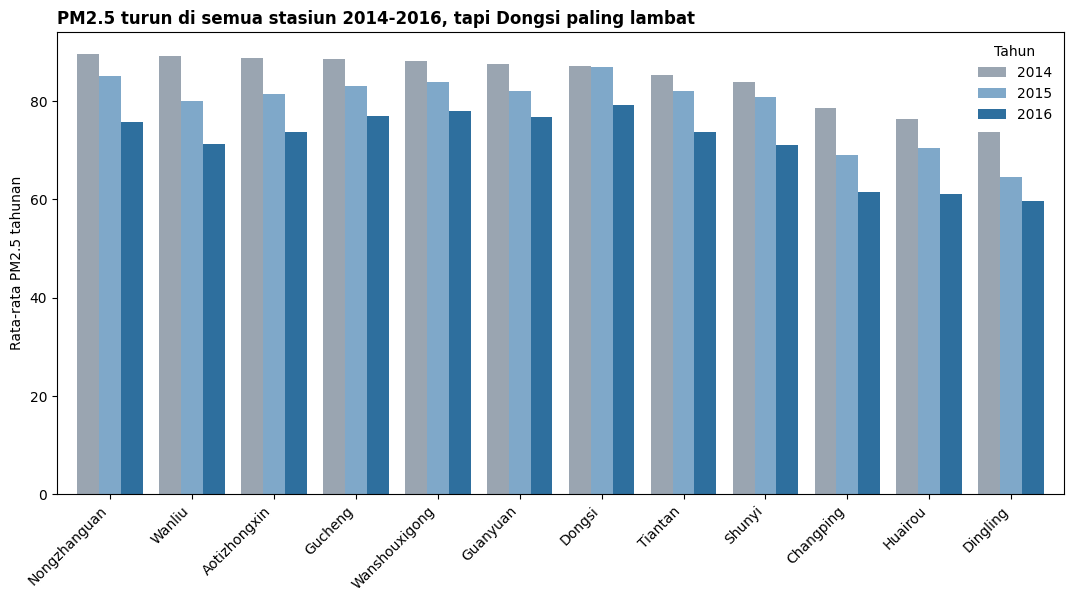

In [ ]:
plot_df_raw = annual[[2014, 2015, 2016]].sort_values(2014, ascending=False)
colors = ["#9AA5B1", "#7FA8C9", "#2E6F9E"]
ax = plot_df_raw.plot(kind="bar", figsize=(13, 6), color=colors, width=0.8)
ax.set_ylabel("Rata-rata PM2.5 tahunan")
ax.set_xlabel("")
ax.set_title('PM2.5 turun di semua stasiun 2014-2016, tapi Dongsi paling lambat', loc="left", fontweight="bold")
ax.legend(title='Tahun', frameon=False)
plt.xticks(rotation=45, ha="right")
plt.show()

### Pertanyaan 2: Ada bulan dan jam berapa kadar PM2.5 paling sering melampaui 150 µg/m³ (Sangat Tidak Sehat)?

In [ ]:
df_raw["above150"] = df_raw["PM2.5"] > 150
MONTHS = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
monthly_df = df_raw.groupby("month")["above150"].mean().mul(100).reset_index()
monthly_df["month_name"] = monthly_df["month"].map(dict(enumerate(MONTHS, 1)))
monthly_df.rename(columns={"above150": "pct_above150"}, inplace=True)
monthly_df.round(1)

,month,pct_above150,month_name
0,1,21.2,Jan
1,2,20.7,Feb
2,3,22.1,Mar
3,4,9.9,Apr
4,5,6.1,Mei
5,6,9.4,Jun
6,7,9.7,Jul
7,8,3.0,Agu
8,9,6.9,Sep
9,10,21.8,Okt


In [ ]:
hourly_df = df_raw.groupby("hour")["above150"].mean().mul(100).reset_index()
hourly_df.rename(columns={"above150": "pct_above150"}, inplace=True)
hourly_df.round(1)

,hour,pct_above150
0,0,16.9
1,1,16.4
2,2,15.9
3,3,15.2
4,4,14.6
5,5,13.5
6,6,12.8
7,7,12.7
8,8,13.1
9,9,13.8


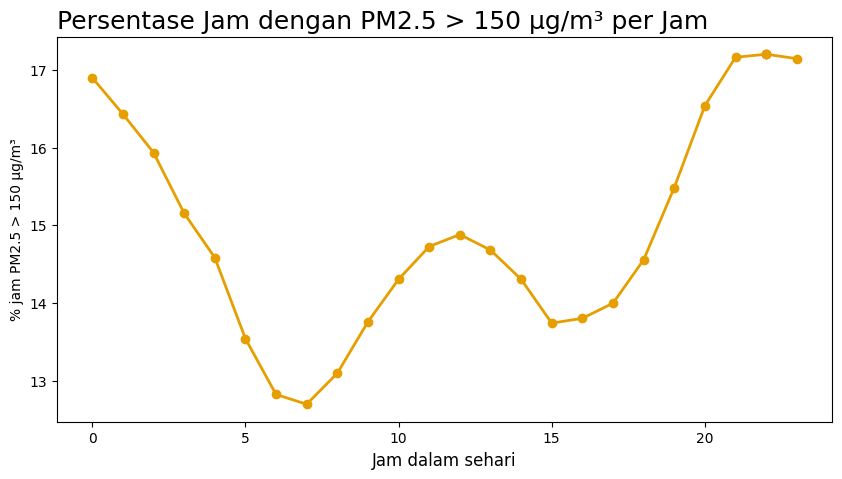

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(hourly_df["hour"], hourly_df["pct_above150"], marker="o", linewidth=2, color="#E69F00")
peak = hourly_df.loc[hourly_df["pct_above150"].idxmax()]
plt.scatter(peak["hour"], peak["pct_above150"], color="#C0392B")
plt.title("Persentase Jam dengan PM2.5 > 150 µg/m³ per Jam", loc="left", fontsize=18)
plt.xlabel("Jam dalam sehari", fontsize=12)
plt.ylabel("% jam PM2.5 > 150 µg/m³", fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

## Pertanyaan 3: Bagaimana hubungan antara angin dan hujan dengan kadar PM2.5 pada musim dingin dibandingkan dengan musim panas?

In [ ]:
sea_df = df_raw[df_raw.season != "Peralihan"].copy()
sea_df["wind_bin"] = pd.cut(sea_df["WSPM"], bins=[-0.01, 1, 2, 3, 4, np.inf], labels=["≤ 1", "1–2", "2–3", "3–4", "> 4"])
sea_df['rain_status'] = np.where(sea_df["RAIN"] > 0, "Hujan (>0mm)", "Tanpa hujan")
wind_df = sea_df.groupby(["wind_bin", 'season'], observed=True)["PM2.5"].mean().reset_index()
rain_df = sea_df.groupby(['rain_status', 'season'])['PM2.5'].mean().reset_index()
print(wind_df.round(1))
print(rain_df.round(1))

  wind_bin        season  PM2.5
0      ≤ 1  Musim Dingin  141.3
1      ≤ 1   Musim Panas   67.7
2      1–2  Musim Dingin  106.7
3      1–2   Musim Panas   65.4
4      2–3  Musim Dingin   51.1
5      2–3   Musim Panas   61.7
6      3–4  Musim Dingin   27.7
7      3–4   Musim Panas   50.6
8      > 4  Musim Dingin   18.4
9      > 4   Musim Panas   39.3
    rain_status        season  PM2.5
0  Hujan (>0mm)  Musim Dingin  124.3
1  Hujan (>0mm)   Musim Panas   59.7
2   Tanpa hujan  Musim Dingin   94.4
3   Tanpa hujan   Musim Panas   64.8


In [ ]:
for s in ['Musim Dingin', 'Musim Panas']:
  d = sea_df[sea_df.season == s]
  print(f"{s}: korelasi WSPM = {d['WSPM'].corr(d['PM2.5'], method='spearman'):.2f}, "
  f"RAIN = {d['RAIN'].corr(d['PM2.5'], method='spearman'):.2f}, "
  f"jam hujan = {(d['RAIN'] > 0).mean() * 100:.1f}%")

Musim Dingin: korelasi WSPM = -0.53, RAIN = 0.05, jam hujan = 0.9%
Musim Panas: korelasi WSPM = -0.09, RAIN = -0.02, jam hujan = 7.0%


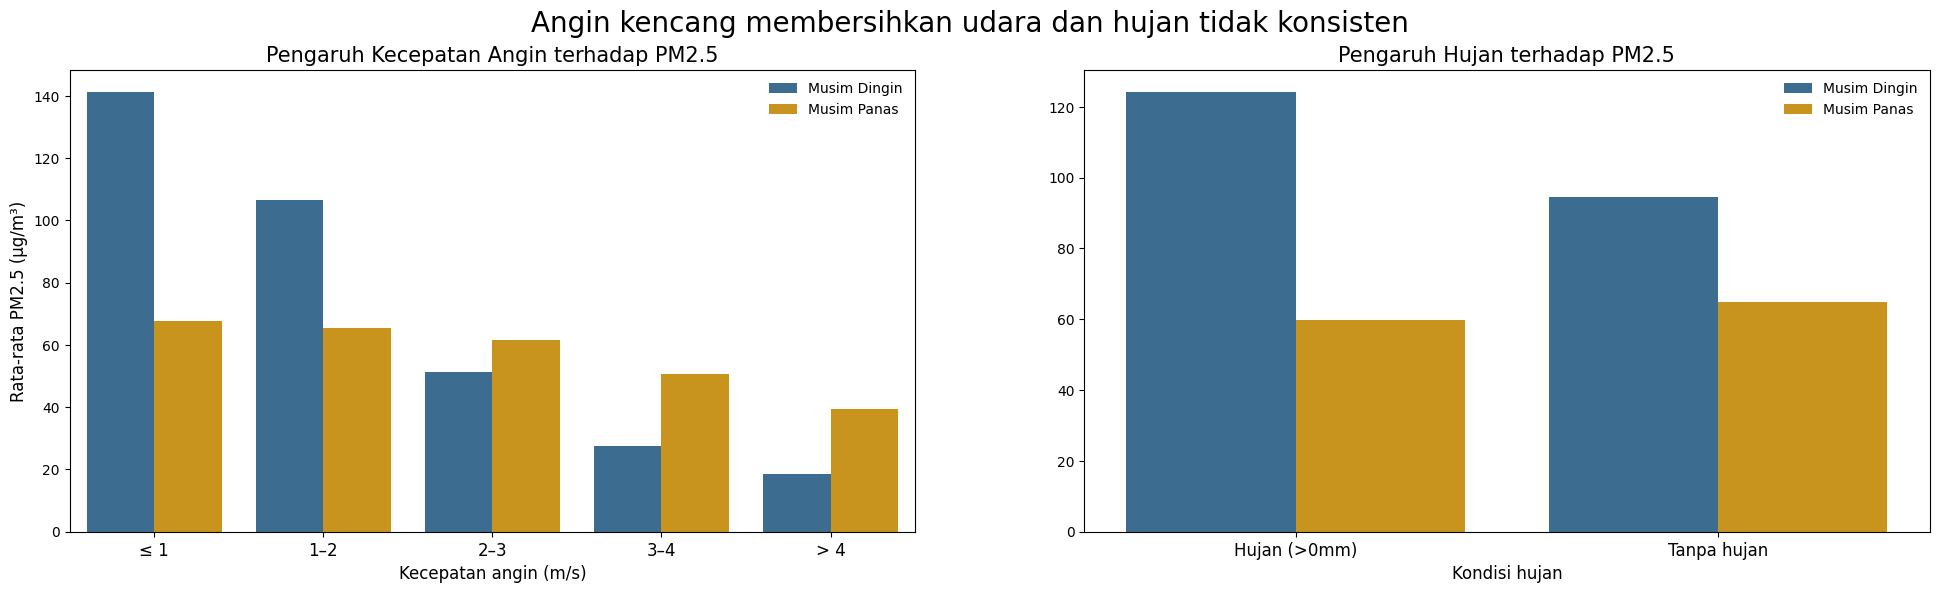

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))
colors = ["#2E6F9E", "#E69F00"]
hue_order = ['Musim Dingin', 'Musim Panas']
sns.barplot(x="wind_bin", y="PM2.5", hue="season", hue_order=hue_order, data=wind_df, palette=colors, ax=ax[0])
ax[0].set_ylabel("Rata-rata PM2.5 (µg/m³)", fontsize=12)
ax[0].set_xlabel("Kecepatan angin (m/s)", fontsize=12)
ax[0].set_title("Pengaruh Kecepatan Angin terhadap PM2.5", loc="center", fontsize=15)
ax[0].tick_params(axis='x', labelsize=12)
ax[0].legend(title=None, frameon=False)
sns.barplot(x="rain_status", y="PM2.5", hue="season", hue_order=hue_order, data=rain_df, palette=colors, ax=ax[1])
ax[1].set_ylabel(None)
ax[1].set_xlabel("Kondisi hujan", fontsize=12)
ax[1].set_title("Pengaruh Hujan terhadap PM2.5", loc="center", fontsize=15)
ax[1].tick_params(axis='x', labelsize=12)
ax[1].legend(title=None, frameon=False)
plt.suptitle("Angin kencang membersihkan udara dan hujan tidak konsisten", fontsize=20)
plt.show()

**Insight:** (Opsional)
- Stasiun dengan PM2.5 tahunan tertinggi: **Nongzhanguan (89,5 µg/m³) pada 2014**, lalu **Dongsi pada 2015 (86,9) dan 2016 (79,2)**. Meski membaik, semua stasiun pada 2016 (59,7-79,2 µg/m³) masih di atas standar tahunan 35 µg/m³.
- **Bulan** adalah faktor penentu utama. Persentase jam di atas 150 µg/m³ paling tinggi pada **Desember (25,5%)**, **November (22,7%)**, Maret (22,1%), Oktober (21,8%), Januari (21,2%), dan Februari (20,7%). Pada **Agustus hanya 3,0%**.
- **Kecepatan angin adalah pembersih utama.** Pada musim dingin, rata-rata PM2.5 turun. **Hujan bukan faktor utama.** Pada musim panas, PM2.5 saat hujan hanya **sekitar 8% lebih rendah** (59,7 vs 64,8). Pada musim dingin, hujan justru bertepatan dengan PM2.5 lebih tinggi (124,3 vs 94,4), tetapi hujan sangat jarang (**0,9% jam**), sehingga hasilnya kemungkinan mencerminkan kondisi udara lembap dan stagnan, bukan efek hujan itu sendiri.

## Analisis Lanjutan (Opsional)

Geospatial Analysis: pola PM2.5 berdasarkan lokasi stasiun
**Tujuan:** melihat apakah tingkat PM2.5 memiliki **pola geografis**, yaitu apakah stasiun yang lebih dekat dengan pusat kota lebih tercemar. Analisis memakai Geopandas: titik stasiun dibuat sebagai data geospasial (`EPSG:4326`, lintang-bujur dalam derajat), lalu dikonversi ke `EPSG:32650` (UTM zona 50N, satuan meter) agar jarak ke pusat kota dapat dihitung dalam kilometer. Koordinat stasiun dan pusat kota adalah **perkiraan** (dataset tidak menyertakan koordinat), cukup untuk melihat pola, bukan untuk pengukuran presisi.

In [ ]:
import geopandas as gpd
data = pd.DataFrame({
    "station": ['Aotizhongxin','Changping','Dingling','Dongsi','Guanyuan','Gucheng', 'Huairou','Nongzhanguan','Shunyi','Tiantan','Wanliu','Wanshouxigong'],
    "lat": [39.982,40.218,40.292,39.929,39.929,39.914,40.328,39.937,40.127,39.886,39.987,39.878],
    "lon": [116.397,116.231,116.220,116.417,116.339,116.184,116.628,116.461,116.655,116.407,116.287,116.352],
})
geo = data.merge(df_raw.groupby("station")["PM2.5"].mean().rename("pm25_mean").reset_index(), on="station")
geo["heavy_pct"] = geo["station"].map(df_raw.groupby("station")["above150"].mean() * 100)
geo.round(1).sort_values('pm25_mean', ascending=False)

,station,lat,lon,pm25_mean,heavy_pct
3,Dongsi,39.9,116.4,85.5,16.9
11,Wanshouxigong,39.9,116.4,84.4,16.3
7,Nongzhanguan,39.9,116.5,84.3,16.5
5,Gucheng,39.9,116.2,83.3,15.6
10,Wanliu,40.0,116.3,83.1,16.1
4,Guanyuan,39.9,116.3,82.4,15.5
0,Aotizhongxin,40.0,116.4,82.0,15.8
9,Tiantan,39.9,116.4,81.6,15.6
8,Shunyi,40.1,116.7,78.9,14.9
1,Changping,40.2,116.2,70.7,12.5


In [ ]:
gdf = gpd.GeoDataFrame(
    geo,
    geometry=gpd.points_from_xy(
        geo.lon,
        geo.lat),
    crs='EPSG:4326'
    )
center = gpd.GeoSeries(gpd.points_from_xy([116.3975], [39.9087]), crs='EPSG:4326').to_crs(epsg=32650)
gdf["dist_center_km"] = gdf.to_crs(epsg=32650).distance(center.iloc[0]) / 1000

print(gdf[["station", "pm25_mean", "heavy_pct", "dist_center_km"]].sort_values("dist_center_km").round(1))
print("\nKorelasi jarak ke pusat vs PM2.5 (Pearson):", round(gdf["dist_center_km"].corr(gdf["pm25_mean"]), 2))
print("Rata-rata PM2.5 stasiun ≤ 15 km dari pusat:", round(gdf[gdf.dist_center_km <= 15].pm25_mean.mean(), 1))
print("Rata-rata PM2.5 stasiun > 15 km dari pusat:", round(gdf[gdf.dist_center_km > 15].pm25_mean.mean(), 1))

          station  pm25_mean  heavy_pct  dist_center_km
9         Tiantan       81.6       15.6             2.6
3          Dongsi       85.5       16.9             2.8
11  Wanshouxigong       84.4       16.3             5.2
4        Guanyuan       82.4       15.5             5.5
7    Nongzhanguan       84.3       16.5             6.3
0    Aotizhongxin       82.0       15.8             8.1
10         Wanliu       83.1       16.1            12.8
5         Gucheng       83.3       15.6            18.3
8          Shunyi       78.9       14.9            32.7
1       Changping       70.7       12.5            37.2
2        Dingling       65.7       11.4            45.2
6         Huairou       69.2       11.7            50.5

Korelasi jarak ke pusat vs PM2.5 (Pearson): -0.92
Rata-rata PM2.5 stasiun ≤ 15 km dari pusat: 83.3
Rata-rata PM2.5 stasiun > 15 km dari pusat: 73.6


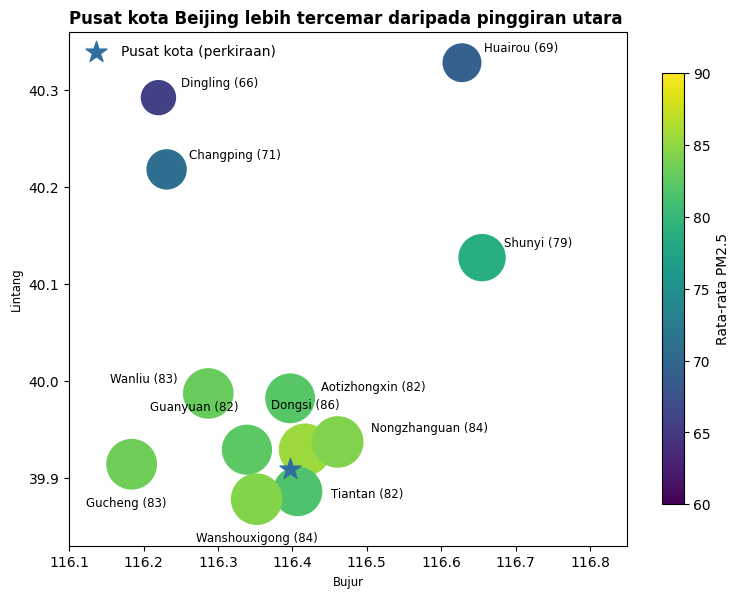

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
gdf.plot(
    ax=ax,
    column='pm25_mean',
    vmin=60,
    vmax=90,
    markersize=(gdf['pm25_mean'] - 50) * 38,
    legend=True,
    legend_kwds={'label': 'Rata-rata PM2.5', 'shrink': 0.8}
    )
gpd.GeoSeries(
    gpd.points_from_xy([116.3975], [39.9087]),
    crs='EPSG:4326').plot(ax=ax,
                          color='#2E6F9E',
                          marker='*',
                          markersize=250,
                          label='Pusat kota (perkiraan)')
offsets = {
    'Guanyuan': (-6, 28, 'right'),
    'Dongsi': (0, 30, 'center'),
    'Nongzhanguan': (24, 8, 'left'),
    'Tiantan': (24, -4, 'left'),
    'Wanshouxigong': (0, -30, 'center'),
    'Aotizhongxin': (22, 6, 'left'),
    'Wanliu': (-22, 8, 'right'),
    'Gucheng': (-4, -30, 'center')
    }
for _, r in gdf.iterrows():
  dx, dy, ha = offsets.get(r.station, (16, 8, 'left'))
  ax.annotate(f'{r.station} ({r.pm25_mean:.0f})', (r.geometry.x, r.geometry.y), textcoords='offset points', xytext=(dx, dy), ha=ha, fontsize=8.5)
ax.set_xlim(116.1, 116.85)
ax.set_ylim(39.83, 40.36)
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
ax.set_title('Pusat kota Beijing lebih tercemar daripada pinggiran utara', loc='left', fontweight='bold')
ax.legend(frameon=False, loc='upper left')
plt.show()

**Insight:** (Opsional)
- Semakin jauh stasiun dari pusat kota, rata-rata PM2.5 cenderung semakin rendah, dengan hanya 12 titik, ini indikasi pola, bukan bukti kuat.
- Stasiun dalam radius 15 km dari pusat rata-rata **83,3 µg/m³**, sedangkan stasiun di luar 15 km rata-rata **73,6 µg/m³**.
- Stasiun pinggiran utara (**Dingling 65,7**, **Huairou 69,2**, **Changping 70,7**) paling bersih, sedangkan **Dongsi (85,5)** paling tercemar.
- **Gucheng** (sekitar 18 km dari pusat, di sisi barat) tetap tinggi (83,3), sehingga jarak ke pusat kota bukan satu-satunya faktor.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Stasiun dengan PM2.5 tahunan tertinggi adalah **Nongzhanguan (2014: 89,5 µg/m³)** dan **Dongsi (2015: 86,9; 2016: 79,2)**. Selama 2014–2016, rata-rata PM2.5 seluruh stasiun turun **±15,6%** (84,7 ke 71,6 µg/m³), dengan penurunan terbesar di **Changping (-21,7%)** dan terkecil di **Dongsi (-9,1%)**. Namun semua stasiun masih di atas standar tahunan 35 µg/m³.
- **Conclusion pertanyaan 2:** PM2.5 melewati 150 µg/m³ pada **14,9% jam**, terkonsentrasi di **Oktober-Maret** (21-26% jam per bulan, tertinggi **Desember 25,5%**), sedangkan Agustus hanya 3,0%. Dalam sehari, **malam hari** paling rawan (hingga 17,2%) dan pagi sekitar 07:00 paling rendah (12,7%).
- **Conclusion pertanyaan 3:** **Kecepatan angin** adalah faktor cuaca paling berpengaruh: pada musim dingin PM2.5 turun dari **141,3 ke 18,4 µg/m³** ketika angin naik dari ≤ 1 ke > 4 m/s, sedangkan pada musim panas efeknya lebih lemah (-0,09). **Hujan** tidak konsisten mengurangi PM2.5 (sekitar -8% di musim panas, tidak ada efek jelas di musim dingin).
- **Kesimpulan analisis lanjutan:** stasiun yang lebih dekat dengan pusat kota cenderung lebih tercemar.

**Rekomendasi Action Item:**
- **Fokuskan pengendalian emisi pada Oktober-Maret**, terutama pembatasan pembakaran batu bara untuk pemanas dan pembatasan kendaraan diesel berat pada malam hari, karena inilah periode ketika polusi berat paling sering terjadi.
- **Jadikan prakiraan angin sebagai pemicu peringatan dini:** pada musim dingin, ketika prakiraan angin ≤ 1-2 m/s, aktifkan peringatan kesehatan dan tindakan darurat sebelum PM2.5 menumpuk, terutama untuk sore hingga malam hari.
- **Prioritaskan stasiun/wilayah pusat kota (Dongsi, Wanshouxigong, Nongzhanguan)** untuk program pengurangan emisi lalu lintas dan pembakaran, karena penurunannya paling lambat dan paparannya tertinggi.
- **Jangan mengandalkan hujan** sebagai pembersih udara; kebijakan perlu bertumpu pada pengurangan emisi, bukan kondisi cuaca.
- **Pantau terus tren 2014-2016** dengan data terbaru, karena level 2016 masih jauh di atas standar tahunan 35 µg/m³.